# Trinkwasserqualität: Analyse und Grenzwert-Compliance
**Prüfbericht (reproduzierbar)** – Reihenfolge: Daten → Qualitätssicherung → Compliance-Logik → SQL-Auswertung → Befunde.

**Datenquellen (alle real und öffentlich):**
1. Michigan, Einzelproben Blei 2016–2019 (APM Reports, Open-Records-Daten, GitHub `APM-Reports/lead-data-analysis`)
2. Landkreis Heilbronn, Jahresmittelwerte je Ortsteil (GitHub `CodeforCologne/trinkwasser`)
3. Open Data Rhein-Neckar, Stand 2014 (ebenfalls in diesem Repo)
4. Rheinenergie Köln, Jahreswerte 2022/2023 (aus den veröffentlichten Trinkwasseranalysen)

**Grenzwerte:** TrinkwV 2023 (Anlage 2/3) und WHO, siehe `data/limits.csv`.

In [1]:
import sys, pandas as pd
sys.path.insert(0, '../src')
import etl, compliance, db
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
limits = pd.read_csv('../data/limits.csv')
limits[['parameter','unit','limit_trinkwv','trinkwv_ref','limit_who','who_type']]

,parameter,unit,limit_trinkwv,trinkwv_ref,limit_who,who_type
0,Blei,mg/L,0.01,"TrinkwV 2023, Anlage 2 Teil II",0.01,gesundheitsbasiert
1,Nitrat,mg/L,50.00,"TrinkwV 2023, Anlage 2 Teil I",50.00,gesundheitsbasiert
2,Chlorid,mg/L,250.00,"TrinkwV 2023, Anlage 3 (Indikatorparameter)",250.00,Akzeptanz
3,Natrium,mg/L,200.00,"TrinkwV 2023, Anlage 3 (Indikatorparameter)",200.00,Akzeptanz
4,Sulfat,mg/L,250.00,"TrinkwV 2023, Anlage 3 (Indikatorparameter)",250.00,Akzeptanz
5,Kalium,mg/L,NaN,NaN,NaN,NaN
6,Calcium,mg/L,NaN,NaN,NaN,NaN
7,Magnesium,mg/L,NaN,NaN,NaN,NaN
8,Gesamthärte,°dH,NaN,NaN,NaN,NaN


## 1 · ETL und Qualitätssicherung
Einheiten werden auf mg/L vereinheitlicht (Michigan liefert MG/L und UG/L gemischt), Bereiche und Mehrfachwerte aus Webtabellen werden konservativ mit dem **Maximum** übernommen, abgelehnte Proben, Duplikate und fehlende Werte werden aus der Prüfung ausgeschlossen – aber nicht gelöscht, sondern über `qc_flag` dokumentiert.

In [2]:
clean = etl.build_clean_table()
dq = compliance.data_quality_report(clean)
dq.set_index('source').T

source,Landkreis Heilbronn (Gemeinden/Stadtwerke),Michigan EGLE / APM Reports,Open Data Rhein-Neckar (2014),Rheinenergie Köln
rows_raw,4040,34543,772,32
rows_used,1160,30946,772,32
excl_missing,91,0,0,0
excl_rejected,0,3596,0,0
excl_duplicate,2824,1,0,0
excl_implausible,0,0,0,0
flag_unit_converted,0,8509,0,0
flag_range_or_multi,41,0,19,0
flag_below_loq,0,0,14,0
flag_nd_zero,0,22401,0,0


In [3]:
clean['qc_flag'].str.split(';').explode().value_counts().to_frame('Anzahl')

,Anzahl
qc_flag,
nd_zero,22401
ok,9189
unit_converted,8509
rejected_NH,3596
duplicate,2825
missing,91
stat_outlier,64
range_max,41
multi_max,19


**Ausreißer:** Statistische Ausreißer (log-IQR-Regel) werden nur *markiert*. Bei Bleiproben sind hohe Werte das eigentliche Signal und keine Messfehler; sie bleiben in der Compliance-Prüfung. Entfernt werden nur physikalisch Unmögliches (negativ, über `plaus_max`) und formal ungültige Proben.

In [4]:
clean[clean.qc_flag.str.contains('stat_outlier')].groupby('parameter')['value'].describe()[['count','min','50%','max']]

,count,min,50%,max
parameter,,,,
Blei,26.0,0.288,0.4215,1.139
Gesamthärte,6.0,24.000,25.0000,26.200
Kalium,8.0,3.800,4.3000,6.600
Natrium,20.0,27.000,33.5500,59.600
Sulfat,4.0,121.000,155.0000,247.000


## 2 · Compliance-Logik
Jeder gültige Wert wird gegen TrinkwV und WHO geprüft. `Überschreitung` = Wert > Grenzwert, `Vorwarnbereich` = ≥ 80 % des Grenzwerts. Parameter ohne Grenzwert (Kalium, Calcium, Magnesium, Härte) werden mitgeführt, aber nicht bewertet.

In [5]:
ev = compliance.evaluate(clean, limits)
ev[ev.use_for_compliance].groupby(['parameter','status']).size().unstack(fill_value=0)

status,Vorwarnbereich (≥80 % GW),eingehalten,kein Grenzwert,Überschreitung
parameter,,,,
Blei,430,29457,0,1059
Calcium,0,0,266,0
Chlorid,0,248,0,0
Gesamthärte,0,0,155,0
Kalium,0,0,248,0
Magnesium,0,0,266,0
Natrium,0,256,0,0
Nitrat,4,261,0,0
Sulfat,1,259,0,0


In [6]:
log = compliance.exceedance_log(ev)
print(len(log), 'Überschreitungen im Protokoll')
log[['station','sample_date','value','ratio_trinkwv','severity','datenherkunft']].head(8)

1059 Überschreitungen im Protokoll


,station,sample_date,value,ratio_trinkwv,severity,datenherkunft
0,AUBURN,2019-07-16,1.1390,113.90,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 1029, R..."
1,MELVINDALE,2019-08-13,1.1000,110.00,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 19598, ..."
2,ROMULUS,2018-01-22,0.9969,99.69,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 24844, ..."
3,"MOUNT CLEMENS, CITY OF",2019-09-26,0.9900,99.00,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 20842, ..."
4,DEXTER,2019-08-07,0.9900,99.00,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 7816, R..."
5,"BAY CITY, CITY OF",2019-10-16,0.8700,87.00,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 2322, R..."
6,ALBION,2018-09-21,0.7610,76.10,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 254, Ro..."
7,EAU CLAIRE,2019-09-23,0.6990,69.90,>5× GW,"mi_system_samples_2016-2019.csv, Zeile 9087, R..."


In [7]:
print(log.loc[0, 'begruendung']); print(log.loc[0, 'bewertungshinweis'])

Blei 1,139 mg/L > Grenzwert 0,01 mg/L (TrinkwV 2023, Anlage 2 Teil II); 113.9× GW; WHO-Status: Überschreitung [gesundheitsbasiert]
Einzelprobe an US-Entnahmestelle (Lead-and-Copper-Rule-Probenahme, i. d. R. Stagnationsproben an Risikohaushalten). Zeigt eine Überschreitung des deutschen/WHO-Zahlenwerts, ist aber keine formale TrinkwV-Grenzwertverletzung.


## 3 · SQL-Auswertung
Die bewertete Tabelle liegt in SQLite; die Abfragen stehen in `sql/queries.sql`.

In [8]:
limits = pd.read_csv('../data/limits.csv')
db.build_db(ev, limits)
sorted(db.load_queries())

['exceedance_rate_parameter',
 'p90_lead_system_year',
 'ranking_critical_parameters',
 'timeseries_monthly',
 'top_stations',
 'trend_quarterly_lead']

In [9]:
db.run('ranking_critical_parameters')

,rang,parameter,n_valid,n_exceed,exceed_rate_pct,max_utilisation_pct
0,1,Blei,30946,1059,3.42,11390.0
1,2,Nitrat,265,0,0.00,100.0
2,3,Sulfat,260,0,0.00,98.8
3,4,Natrium,256,0,0.00,29.8
4,5,Chlorid,248,0,0.00,28.8


In [10]:
db.run('exceedance_rate_parameter')

,parameter,source,n_valid,n_exceed,exceed_rate_pct,n_warn,max_utilisation_pct
0,Blei,Michigan EGLE / APM Reports,30946,1059,3.42,430,11390.0
1,Nitrat,Open Data Rhein-Neckar (2014),112,0,0.00,4,100.0
2,Sulfat,Landkreis Heilbronn (Gemeinden/Stadtwerke),149,0,0.00,1,98.8
3,Nitrat,Landkreis Heilbronn (Gemeinden/Stadtwerke),149,0,0.00,0,74.6
4,Sulfat,Open Data Rhein-Neckar (2014),107,0,0.00,0,47.2
5,Nitrat,Rheinenergie Köln,4,0,0.00,0,42.0
6,Natrium,Open Data Rhein-Neckar (2014),112,0,0.00,0,29.8
7,Sulfat,Rheinenergie Köln,4,0,0.00,0,29.2
8,Chlorid,Open Data Rhein-Neckar (2014),111,0,0.00,0,28.8
9,Chlorid,Rheinenergie Köln,4,0,0.00,0,25.6


In [11]:
db.run('timeseries_monthly').query("parameter=='Blei'").sort_values('n_samples', ascending=False).head(10)

,station_id,station,parameter,month,n_samples,mean_value,max_value,n_exceed
1272,MI0000690,BEVERLY HILLS,Blei,2018-12,166,0.00031,0.0085,0
1270,MI0000690,BEVERLY HILLS,Blei,2018-06,130,0.00035,0.0160,1
1210,MI0000465,BAY AREA WATER SYSTEM,Blei,2018-09,102,0.00387,0.1710,5
1204,MI0000465,BAY AREA WATER SYSTEM,Blei,2016-09,99,0.00553,0.0990,17
1205,MI0000465,BAY AREA WATER SYSTEM,Blei,2017-03,99,0.00248,0.0200,6
1208,MI0000465,BAY AREA WATER SYSTEM,Blei,2018-03,99,0.00226,0.0550,3
1206,MI0000465,BAY AREA WATER SYSTEM,Blei,2017-09,99,0.00775,0.4100,9
2019,MI0002745,CHARTER TOWNSHIP OF GRAND BLANC,Blei,2018-05,67,0.00115,0.0420,2
3365,MI0006440,STURGIS,Blei,2018-06,66,0.00118,0.0350,2
2719,MI0004570,MUSKEGON,Blei,2017-06,65,0.00209,0.0620,1


In [12]:
db.run('trend_quarterly_lead')

,quarter,n_valid,n_exceed,exceed_rate_pct
0,2016-Q1,132,3,2.27
1,2016-Q2,820,19,2.32
2,2016-Q3,2686,97,3.61
3,2016-Q4,500,18,3.60
4,2017-Q1,244,9,3.69
5,2017-Q2,1640,31,1.89
6,2017-Q3,4747,115,2.42
7,2017-Q4,406,13,3.20
8,2018-Q1,525,16,3.05
9,2018-Q2,1742,40,2.30


In [13]:
db.run('top_stations').head(10)

,station_id,station,source,n_valid,n_exceed,exceed_rate_pct,max_value,first_date,last_date
0,MI0005200,PARCHMENT,Michigan EGLE / APM Reports,133,70,52.6,0.3300,2017-08-09,2019-10-31
1,MI0000600,BENTON HARBOR,Michigan EGLE / APM Reports,115,43,37.4,0.0720,2018-09-17,2019-12-21
2,MI0000465,BAY AREA WATER SYSTEM,Michigan EGLE / APM Reports,503,40,8.0,0.4100,2016-09-13,2018-09-14
3,MI0003520,KALAMAZOO,Michigan EGLE / APM Reports,373,36,9.7,0.1500,2016-06-06,2019-11-21
4,MI0002180,"ESSEXVILLE, CITY OF",Michigan EGLE / APM Reports,80,23,28.8,0.1000,2019-04-29,2019-11-01
5,MI0002970,HAMTRAMCK,Michigan EGLE / APM Reports,128,22,17.2,0.0330,2018-09-21,2019-12-30
6,MI0004880,OAK PARK,Michigan EGLE / APM Reports,36,17,47.2,0.0390,2017-08-08,2019-09-26
7,MI0003120,HERMANSVILLE HOUSING COMM.,Michigan EGLE / APM Reports,50,16,32.0,0.2230,2016-06-14,2019-12-23
8,MI0000470,"BAY CITY, CITY OF",Michigan EGLE / APM Reports,120,14,11.7,0.8700,2019-04-02,2019-11-06
9,MI0002550,GARDEN CITY,Michigan EGLE / APM Reports,37,14,37.8,0.0474,2017-06-16,2019-09-09


In [14]:
p90 = db.run('p90_lead_system_year'); print(len(p90), 'System-Jahre mit n>=5; davon über 15 µg/L:', int(p90.above_epa_action_level.sum())); p90.head(8)

2123 System-Jahre mit n>=5; davon über 15 µg/L: 83


,station_id,station,year,n,p90_ug_l,above_epa_action_level
0,MI0002030,EAU CLAIRE,2019,9,699.0,1
1,MI0004220,MELVINDALE,2019,30,370.0,1
2,MI0000690,BEVERLY HILLS,2017,6,228.3,1
3,MI0040028,VILLAGE EAST ESTATES,2017,7,190.0,1
4,MI0062841,MEDILODGE OF STERLING,2016,5,134.0,1
5,MI0005785,ROMULUS,2017,8,120.0,1
6,MI0003140,HIGHLAND PARK,2019,36,100.0,1
7,MI0006042,SHERWOOD SHORES CONDOMINIUMS,2017,5,100.0,1


## 4 · Dashboard-Vorschau (Python)
Das Tableau-Dashboard nutzt dieselben Daten aus `tableau/`; diese Grafik dient als Kontrollansicht.

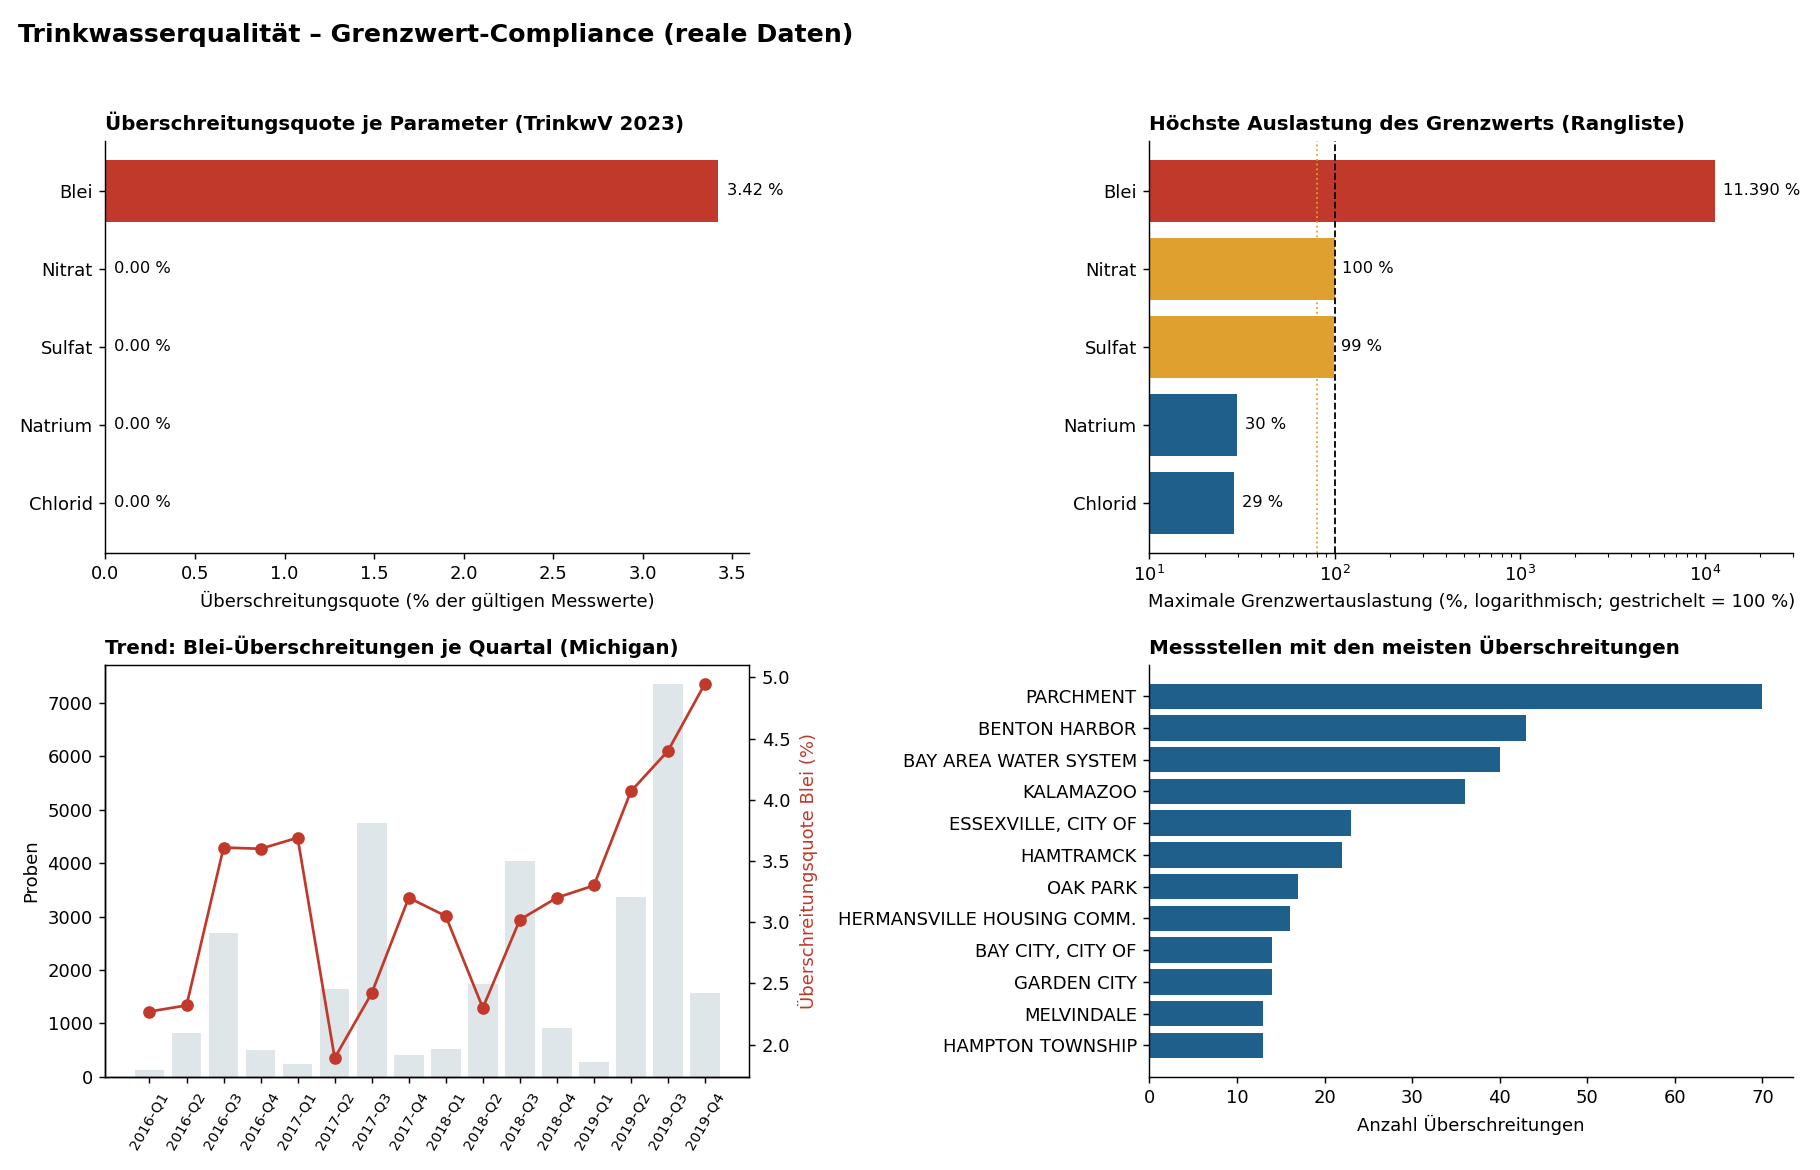

In [15]:
from IPython.display import Image
Image('../reports/figures/dashboard_preview.png')

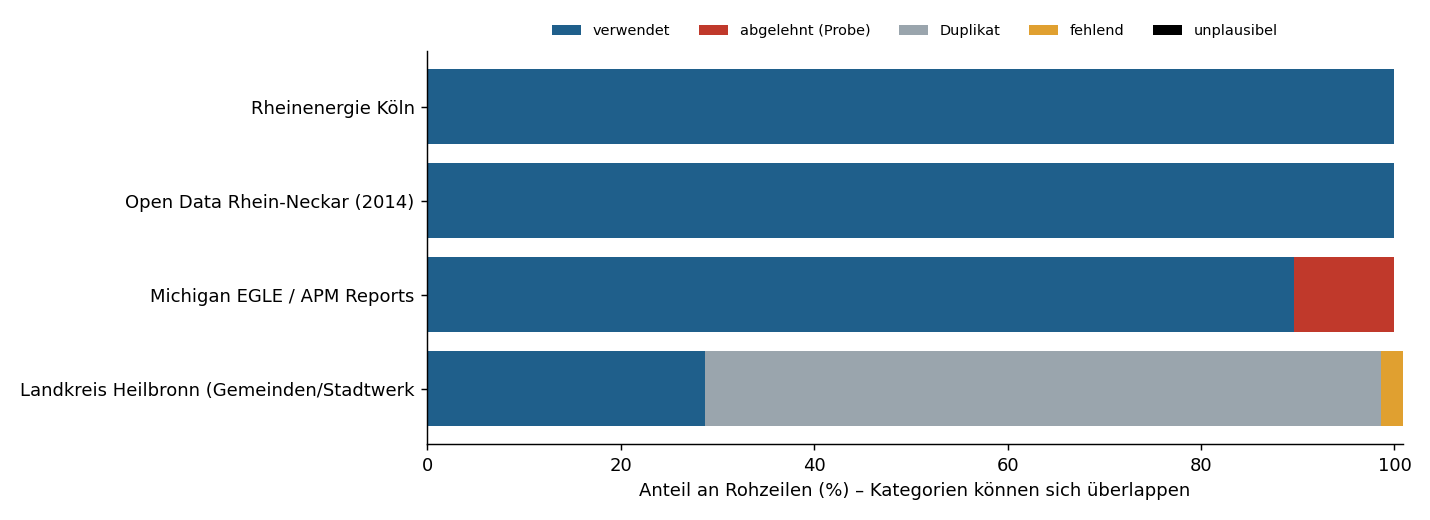

In [16]:
Image('../reports/figures/data_quality.png')

## 5 · Befunde und Grenzen
* **Blei ist der einzige Parameter mit Überschreitungen:** rund 3,4 % der gültigen Michigan-Proben liegen über 10 µg/L, einzelne Proben bis zum ~114-Fachen des Grenzwerts.
* **Nitrat, Sulfat, Natrium, Chlorid** halten in den deutschen Daten den Grenzwert ein. Nitrat erreicht in einem Rhein-Neckar-Eintrag exakt 100 % des Grenzwerts (50 mg/L, nicht überschritten), Sulfat 98,8 %: das sind die Kandidaten für eine Beobachtung.
* **Trend:** Die Quote steigt von 2016 bis 2019 von ca. 2 % auf ca. 5 %. Achtung, das ist *kein* belastbarer Trend: Anzahl und Auswahl der Proben ändern sich stark von Quartal zu Quartal (siehe Balken).
* **Nicht vergleichbar:** Die US-Proben sind Einzelproben nach Lead-and-Copper-Rule-Protokoll (Stagnation, Risikohaushalte), die deutschen Werte sind veröffentlichte Jahresmittel. Eine Überschreitung in den US-Daten ist deshalb *kein* TrinkwV-Verstoß, sondern ein Zahlenvergleich gegen den Grenzwert.
* **Bereiche** wurden mit dem Maximum angesetzt (konservativ), `Nicht nachweisbar` bei Blei als 0 behandelt.
* Chlorid fehlt in vielen Heilbronner Datensätzen; die WHO-Werte für Natrium, Chlorid und Sulfat sind Geschmacksschwellen, keine Gesundheitswerte.